# Breast Cancer Wisconsin — Diagnostic
### Context

Clinical imaging dataset describing breast masses using quantitative characteristics extracted from digitised images of fine-needle aspirates. The variables describe different morphological properties of cell nuclei.

### Dimensionality and Structure

The dataset contains 569 samples described by 30 continuous variables. Each sample is associated with a binary diagnosis: benign or malignant.

### Possible Questions

Supervised learning: Predict whether a breast mass is benign or malignant.
Unsupervised learning: Determine whether samples naturally separate into groups corresponding to benign and malignant diagnoses.
Additional analysis: Identify the morphological variables that are the most discriminative.


# Unsupervised learning

### 1.Import Library

In [22]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

### 2.Data 

In [6]:
breast_data = pd.read_csv('/Users/apple/Desktop/Project UE1_AIDA/10_Breast_Cancer_Wisconsin_Diagnostic.csv')
print(breast_data.head())
print(breast_data.shape)
print(breast_data.info())

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  perimeter_worst  area_wor

### 3. Preprocessing

The features are then standardized using the 'StandardScaler'. This step is important because the variables have different scales and ranges. Standardization centers each variable around zero and scales it to have a standard deviation of one.

This preprocessing step is particularly important for distance-based clustering methods such as K-means and Agglomerative Clustering.

In [7]:
#Remove "id" and "diagnosis"
data_features = breast_data.drop(["id", "diagnosis"], axis=1)

#Change M into 0 and B into 1
breast_data["diagnosis"] = breast_data["diagnosis"].map({"M": 0, "B": 1})

We remove the 'id' variable because it is only a patient identifier and does not contain relevant biological informations for clustering.

The 'diagnosis' variable is also excluded from the features used to build the clusters. It indicates whether the tumor is malignant or benign and therefore represents the target variable. Including it during clustering would introduce supervised information into an unsupervised analysis.

The remaining 30 morphological variables are therefore used as input features.

In [8]:
#Standardization
scaler = StandardScaler()
features_scaled = scaler.fit_transform(data_features)

### 4. K-means Clustering

K-means is a clustering algorithm that partitions observations into a predefined number of groups, called clusters.

The algorithm initially assigns observations to cluster centroids and then iteratively updates the centroids and cluster assignments. Each observation is assigned to the closest centroid based on the Euclidean distance.

In this analysis, two clusters are initially considered. The appropriate number of clusters is subsequently evaluated using the Elbow Method and the Silhouette Score.

Importantly, the diagnosis is not used during model fitting. The clusters are therefore constructed exclusively from the 30 morphological features.

In [9]:
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_clusters = kmeans.fit_predict(features_scaled)
breast_data["km_cluster"] = kmeans_clusters

### 5. Agglomerative Clustering

Agglomerative Clustering is a hierarchical clustering method.

Unlike K-means, which starts by defining a fixed number of clusters, the agglomerative approach initially considers each observation as an individual cluster. The closest clusters are then progressively merged until all observations belong to a single cluster.

The resulting hierarchical structure can be represented using a dendrogram.

In this analysis, Ward's linkage method is used. This method selects the merge that results in the smallest increase in within-cluster variance.

As with K-means, the clustering algorithm is applied exclusively to the 30 standardized morphological features and does not use the diagnosis.

In [24]:
#Agglomerative clustering
agg = AgglomerativeClustering(n_clusters=2)
agg_clusters = agg.fit_predict(features_scaled)

breast_data["agg_cluster"] = agg_clusters

### 6. Comparison with the True Diagnosis

Although the diagnosis was not used to construct the clusters, it can be used retrospectively to evaluate how well the identified clusters correspond to the actual clinical categories.

A contingency table is used to compare the cluster assignments with the true diagnosis.

It is important to note that cluster labels are arbitrary. For example, Cluster 0 does not inherently represent malignant tumors and Cluster 1 does not inherently represent benign tumors. The interpretation of the clusters is performed only after comparing them with the known diagnoses.

In [32]:
table_km = pd.crosstab(breast_data["diagnosis"], breast_data["km_cluster"])
accuracy_km = accuracy_score(breast_data["diagnosis"], breast_data["km_cluster"])

print(table_km)
print("Accuracy for the k-means =", accuracy_km)

table_agg = pd.crosstab(breast_data["diagnosis"],breast_data["agg_cluster"])
accuracy_agg = accuracy_score(breast_data["diagnosis"], breast_data["agg_cluster"])
print(table_agg)
print("Accuracy for the Agglomerative Clustering =", accuracy_agg)

km_cluster    0    1
diagnosis           
0           175   37
1            13  344
Accuracy for the k-means = 0.9121265377855887
agg_cluster    0    1
diagnosis            
0            164   48
1             20  337
Accuracy for the Agglomerative Clustering = 0.8804920913884007


#### Contingency table 1 
It's shows that Cluster 0 mainly contains patients with malignant tumors, whereas Cluster 1 mainly contains patients with benign tumors.
The agreement between the K-means clusters and the true diagnosis is 91.21%.
This result indicates that the unsupervised algorithm identifies a structure that is strongly associated with the actual diagnosis, despite the diagnosis not being used during model training.

#### Contingency table 2
The clusters obtained with Agglomerative Clustering are compared retrospectively with the true diagnosis using a contingency table.
Cluster 0 is predominantly composed of patients with malignant tumors, whereas Cluster 1 is predominantly composed of patients with benign tumors.
The agreement between the clusters and the true diagnosis is 88.05%.
This result indicates that Agglomerative Clustering also identifies a structure that is strongly associated with the clinical diagnosis, although its agreement is slightly lower than that obtained with K-means.

### 7. Silhouette score

The Silhouette Score evaluates the quality of a clustering by considering both the cohesion of observations within their own cluster and their separation from other clusters.

The score ranges from -1 to 1:

- a value close to 1 indicates well-separated clusters;
- a value close to 0 indicates overlapping clusters;
- a negative value may indicate that observations have been assigned to an inappropriate cluster.

The Silhouette Score is calculated for different values of K in order to identify the number of clusters providing the best separation according to this criterion.

Text(0.5, 1.0, 'Agglomerative Clustering')

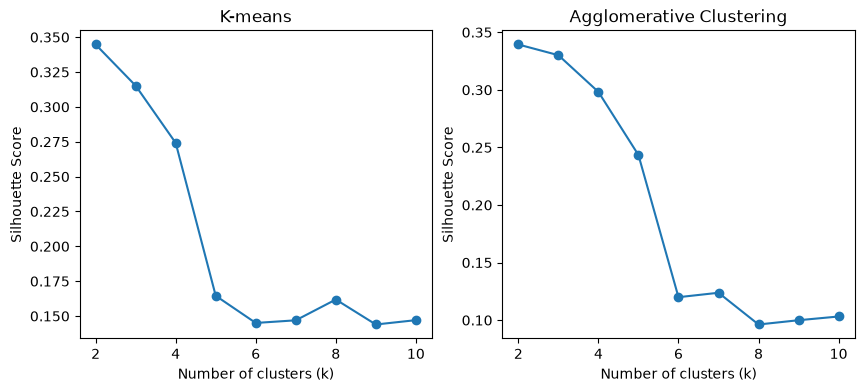

In [37]:
silhouette_kmeans = []
silhouette_agg = []

# Create one figure with two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))


# Silhouette Score for K-means

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    clusters = kmeans.fit_predict(features_scaled)

    score = silhouette_score(features_scaled, clusters)
    silhouette_kmeans.append(score)

axes[0].plot(range(2, 11), silhouette_kmeans, marker="o")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_title("K-means")


# Silhouette Score for Agglomerative Clustering

for k in range(2, 11):
    agg = AgglomerativeClustering(n_clusters=k)
    clusters = agg.fit_predict(features_scaled)

    score = silhouette_score(features_scaled, clusters)
    silhouette_agg.append(score)

axes[1].plot(range(2, 11), silhouette_agg, marker="o")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Agglomerative Clustering")

The highest Silhouette Score for the K-means method is obtained for K = 2, with a score of approximately 0.345.
Higher values of K result in lower Silhouette Scores.

The Silhouette Score is also calculated for Agglomerative Clustering in order to compare its intrinsic clustering quality with that of K-means. The obtained Silhouette Score is 0.339.
This value is slightly lower than the score obtained with K-means (approximately 0.345). However, the difference is small, suggesting that both methods identify a relatively similar underlying structure in the dataset.

### 8. Principal Component Analysis

Principal Component Analysis (PCA) is used to reduce the dimensionality of the dataset and visualize the clustering results in a two-dimensional space.

PCA transforms the original variables into a new set of variables called principal components. Each principal component is a linear combination of the original features and is ordered according to the amount of variance it explains.

The first principal component (PC1) captures the largest possible proportion of the variance in the dataset, while the second principal component (PC2) captures the largest proportion of the remaining variance.

PCA is performed on the 30 standardized morphological features and does not include the diagnosis.

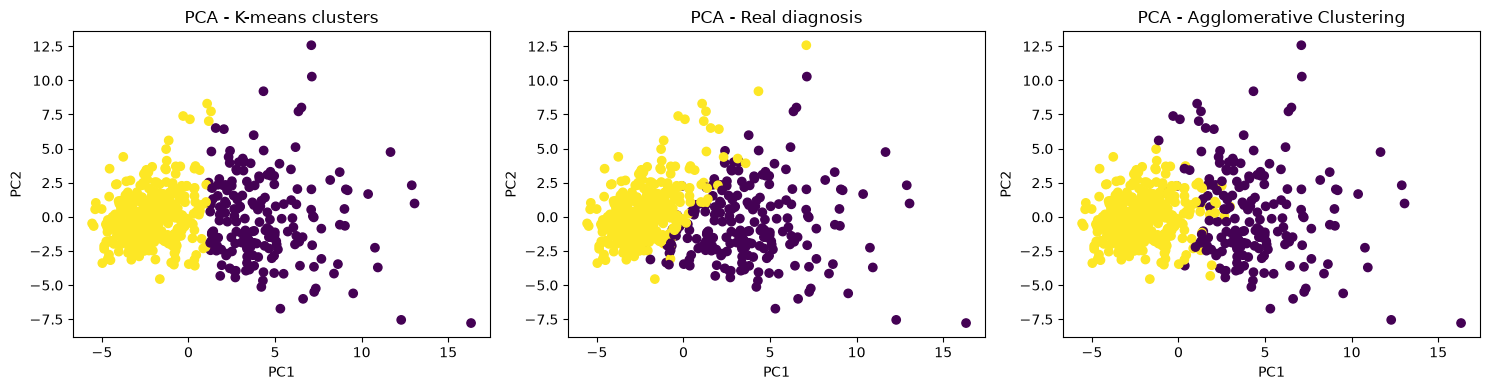

In [38]:
pca = PCA(n_components=2)
features_pca = pca.fit_transform(features_scaled)

# Create one figure with three plots side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))


# PCA with K-means clusters
axes[0].scatter(features_pca[:, 0],features_pca[:, 1],c=breast_data["km_cluster"])
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].set_title("PCA - K-means clusters")


# PCA with real diagnosis
axes[1].scatter(features_pca[:, 0],features_pca[:, 1],c=breast_data["diagnosis"])
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("PCA - Real diagnosis")


# PCA with Agglomerative Clustering
axes[2].scatter(features_pca[:, 0],features_pca[:, 1],c=breast_data["agg_cluster"])
axes[2].set_xlabel("PC1")
axes[2].set_ylabel("PC2")
axes[2].set_title("PCA - Agglomerative Clustering")


# Adjust spacing
plt.tight_layout()

plt.show()

In [17]:
#Importance of each component
pca_components = pd.DataFrame(pca.components_,columns=data_features.columns,index=["PC1", "PC2"])
print(pca_components.loc["PC1"].abs().sort_values(ascending=False))

#how much PC1 and PC2 are important
print(pca.explained_variance_ratio_.sum())
print(pca.explained_variance_ratio_)

concave_points_mean        0.260854
concavity_mean             0.258400
concave_points_worst       0.250886
compactness_mean           0.239285
perimeter_worst            0.236640
concavity_worst            0.228768
radius_worst               0.227997
perimeter_mean             0.227537
area_worst                 0.224871
area_mean                  0.220995
radius_mean                0.218902
perimeter_se               0.211326
compactness_worst          0.210096
radius_se                  0.205979
area_se                    0.202870
concave_points_se          0.183417
compactness_se             0.170393
concavity_se               0.153590
smoothness_mean            0.142590
symmetry_mean              0.138167
fractal_dimension_worst    0.131784
smoothness_worst           0.127953
symmetry_worst             0.122905
texture_worst              0.104469
texture_mean               0.103725
fractal_dimension_se       0.102568
fractal_dimension_mean     0.064363
symmetry_se                0

The proportion of explained variance indicates how much of the information contained in the original dataset is retained by each principal component.In this analysis, PC1 explains 44.27% of the total variance, while PC2 explains 18.97%.
Together, the first two principal components explain 63.24% of the total variance.

Therefore, the two-dimensional PCA representation retains a substantial proportion of the variability present in the original 30-dimensional dataset. However, approximately 36.76% of the variance is represented by the remaining principal components.
The coefficients, or loadings, of the first principal component can be examined to identify the variables contributing most strongly to the variance represented by PC1.

The features with the largest absolute loadings include 'concave_points_mean', 'concavity_mean', 'concave_points_worst', 'compactness_mean', 'perimeter_worst', 'concavity_worst', as well as several variables related to radius, perimeter, and area.
PC1 is therefore mainly influenced by morphological characteristics related to the size and shape of cell nuclei.
However, PC1 should not be interpreted as a "cancer axis". PCA is an unsupervised dimensionality reduction technique that maximizes variance in the dataset rather than specifically maximizing the separation between benign and malignant tumors.

## Comparison of Clustering Methods

Both clustering methods identify two main groups within the dataset.
K-means achieves a Silhouette Score of approximately 0.345 and an agreement of 91.21% with the true diagnosis. Agglomerative Clustering achieves a Silhouette Score of 0.339 and an agreement of 88.05%.

The Silhouette Scores are very similar, indicating that both methods identify a comparable underlying structure in the data. However, K-means performs slightly better according to both evaluation criteria.

The PCA visualizations also show a similar separation of the two clusters, mainly along the first principal component. Nevertheless, some overlap between the clusters remains, indicating that certain patients have intermediate morphological characteristics and cannot be perfectly separated.

Importantly, the diagnosis was not used during the training of either clustering algorithm. The comparison with the diagnosis therefore represents a retrospective evaluation of the clinical relevance of the identified clusters.